# CITE-seq PBMCs: From Clusters to Single Cells with RNA and Protein

Cellular indexing of transcriptomes and epitopes by sequencing (CITE-seq) measures gene expression and surface proteins in the same cells, using antibodies tagged with DNA barcodes (antibody-derived tags, ADTs). This tutorial explores 12,242 human peripheral blood mononuclear cells (PBMCs) profiled with 10x Genomics Flex v2 and the TotalSeq-C Human Universal Cocktail v2.0, which measures 184 surface proteins alongside 18,132 genes.

A UMAP shows how cells group, but not what makes the groups different. Celldega links a UMAP to Clustergrams of the genes and proteins behind each group, and the Clustergram's dendrograms let you move up and down the hierarchy of cell types. We work through three levels:

1. **Clusters:** a cluster Clustergram linked to the UMAP helps decide how to filter low-quality cells.
2. **Cell types:** cell types are named from their RNA and protein markers, and one Clustergram compares the two modalities.
3. **Single cells:** individual B cells are clustered by their genes and proteins together, which reveals suspected doublets hiding inside a B-cell cluster.

This tutorial updates the CITE-seq examples of the [Clustergrammer2 notebooks](https://github.com/ismms-himc/clustergrammer2-notebooks), which assigned PBMC cell types by clustering antibody data ([4.0](https://nbviewer.org/github/ismms-himc/clustergrammer2-notebooks/blob/master/notebooks/4.0_10K_PBMC_CITE-seq_Assign_Cell_Type.ipynb)) and labeled them in linked views ([4.2](https://nbviewer.org/github/ismms-himc/clustergrammer2-notebooks/blob/master/notebooks/4.2_CITE-seq_Manually_Label_Linked_Views.ipynb)). The Scanpy steps follow the [Chromium PBMC tutorial](../Scanpy_Chromium/), which explains them in more detail.

Data: [16k Human PBMCs, TotalSeq-C 4-plex (Flex v2)](https://www.10xgenomics.com/datasets/Flexv2_16k_Human_PBMCs_TotalseqC_4plex), provided by 10x Genomics under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), packaged into a MuData by the [pre-process notebook](https://huggingface.co/datasets/broadinstitute/Celldega_Supporting_Data/blob/main/Flex_16k_PBMC_CITE-seq/Flex_16k_PBMC_CITE-seq_Pre-process.ipynb) hosted with Celldega's supporting data on Hugging Face.

## Setup

Use Python 3.11 or 3.12 and Celldega 0.27.0 or later. Install the notebook dependencies in the environment used by your Jupyter kernel:

```python
%pip install "celldega[scanpy]>=0.27.0" igraph ipykernel
```

The Landscape reads DegaFiles for this dataset hosted on GitHub, and Enrich queries the public Enrichr service. Both need an internet connection. The saved interactive widgets on this documentation page work without a running Python kernel.

In [1]:
from pathlib import Path
import shutil
from urllib.request import Request, urlopen

import anndata as ad
import celldega as dega
import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
from pandas.errors import PerformanceWarning
import scanpy as sc
import warnings

sc.settings.verbosity = 1
# Scanpy's fold changes assume non-negative values; CLR protein values can be negative.
warnings.filterwarnings("ignore", category=RuntimeWarning, module=r"scanpy\.tools\._rank_genes_groups")
warnings.filterwarnings("ignore", category=PerformanceWarning, module=r"scanpy\.tools\._rank_genes_groups")

## Load the MuData

The MuData holds raw counts in two modalities over the same cells: `rna` for genes and `prot` for antibodies. Many antibody targets share a name with a gene, so proteins are named by their target with a `_prot` suffix (`CD4_prot` next to the `CD4` gene). The nine isotype controls, antibodies with no human target that measure background binding, are flagged in `prot.var`. The file is downloaded once and cached locally.

In [2]:
DATA_URL = "https://huggingface.co/datasets/broadinstitute/Celldega_Supporting_Data/resolve/main/Flex_16k_PBMC_CITE-seq"
# DegaFiles (one count file per gene and protein) are hosted on GitHub.
DEGA_FILES_URL = "https://raw.githubusercontent.com/broadinstitute/Celldega_16k_Human_PBMCs_TotalseqC_4plex_PBMC_TotalSeqC/main"

# Reuse the repository's notebook data directory when running from a checkout;
# otherwise cache the download beside the notebook.
working_dir = Path.cwd().resolve()
project_root = next(
    (
        directory
        for directory in (working_dir, *working_dir.parents)
        if (directory / "pyproject.toml").is_file() and (directory / "notebooks").is_dir()
    ),
    None,
)
data_dir = (project_root / "notebooks" if project_root else working_dir) / "data"
data_dir = data_dir / "16k_Human_PBMCs_TotalseqC_4plex_PBMC_TotalSeqC"
data_dir.mkdir(parents=True, exist_ok=True)

h5mu_path = data_dir / "Flex_16k_PBMC_CITE-seq.h5mu"
if not h5mu_path.is_file():
    partial = h5mu_path.with_suffix(".h5mu.part")
    request = Request(f"{DATA_URL}/{h5mu_path.name}", headers={"User-Agent": "celldega-example-notebook"})
    print("Downloading the CITE-seq MuData...")
    try:
        with urlopen(request, timeout=300) as response, partial.open("wb") as output:
            shutil.copyfileobj(response, output, length=1024 * 1024)
        partial.replace(h5mu_path)
    except Exception:
        partial.unlink(missing_ok=True)
        raise

# Adopt the upcoming MuData default: update() no longer pulls modality columns.
md.set_options(pull_on_update=False)
mdata = md.read_h5mu(h5mu_path)
rna, prot = mdata.mod["rna"], mdata.mod["prot"]
rna.obs["sample"] = mdata.obs["sample"]
print(mdata)

MuData object with n_obs × n_vars = 12242 × 18316
  obs:	'sample'
  uns:	'source'
  2 modalities
    rna:	12242 x 18132
      obs:	'sample'
      var:	'gene_ids', 'feature_types'
    prot:	12242 x 184
      var:	'gene_ids', 'feature_types', 'antibody', 'isotype_control'


## QC metrics, normalization, and clustering

From RNA, compute the counts, genes detected, and percent mitochondrial counts of every cell. From protein, compute the total antibody counts and the percent of them that come from isotype controls.

RNA is normalized and clustered as in the Chromium tutorial: log counts per 10,000, highly variable genes, PCA, a neighbor graph, UMAP, and Leiden clusters. Proteins are normalized with a centered log ratio (CLR) per cell, which subtracts the cell's mean log count across antibodies from each antibody's log count and so removes differences in total antibody capture between cells. Raw counts stay in `layers["counts"]` of both modalities.

In [3]:
rna.var["mt"] = rna.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(rna, qc_vars=["mt"], percent_top=None, inplace=True)

adt_counts = prot.X.toarray()
isotype = prot.var["isotype_control"].to_numpy()
rna.obs["protein_counts"] = adt_counts.sum(axis=1)
rna.obs["pct_isotype"] = 100 * adt_counts[:, isotype].sum(axis=1) / rna.obs["protein_counts"]

rna.layers["counts"] = rna.X.copy()
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna, n_top_genes=2000)
sc.tl.pca(rna, mask_var="highly_variable", random_state=0)
sc.pp.neighbors(rna, n_neighbors=15, n_pcs=30, random_state=0)
sc.tl.umap(rna, random_state=0)
sc.tl.leiden(
    rna, flavor="igraph", directed=False, n_iterations=2, resolution=1.0, random_state=0, key_added="leiden"
)

prot.layers["counts"] = prot.X.copy()
log_counts = np.log1p(adt_counts)
prot.X = log_counts - log_counts.mean(axis=1, keepdims=True)

rna.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt", "protein_counts", "pct_isotype"]].describe().round(1)

,total_counts,n_genes_by_counts,pct_counts_mt,protein_counts,pct_isotype
count,12242.0,12242.0,12242.0,12242.0,12242.0
mean,11089.8,3764.9,1.3,8244.5,0.5
std,7371.9,1213.9,4.3,7752.4,0.3
min,494.0,129.0,0.0,55.0,0.0
25%,6376.0,3106.0,0.3,3358.2,0.3
50%,8136.5,3580.0,0.5,5419.5,0.4
75%,16413.2,4716.0,1.0,11819.5,0.5
max,132003.0,8838.0,81.0,103382.0,4.1


The four probe-barcoded samples spread evenly over the UMAP, so we analyze them together. Plotting the clusters also stores Scanpy's cluster palette, which the Landscape and Clustergram reuse.

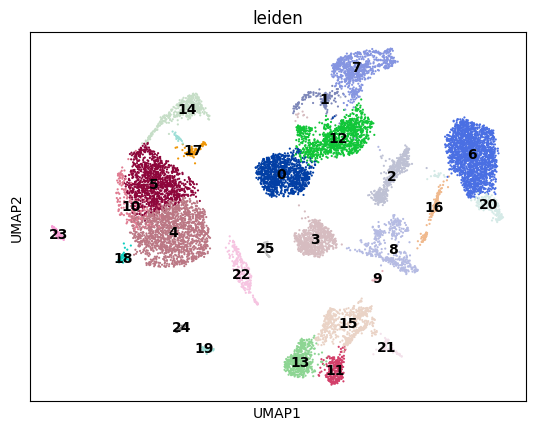

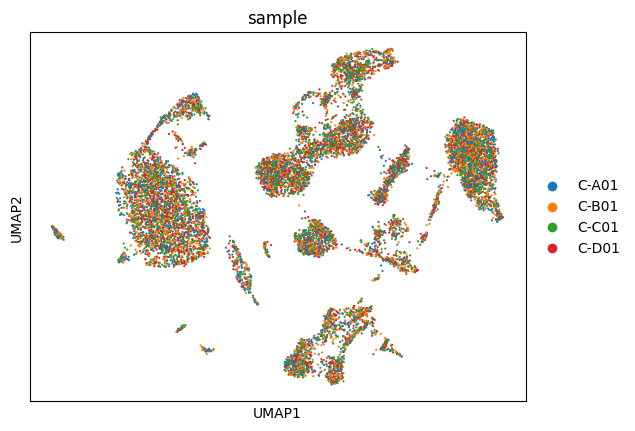

In [4]:
sc.pl.umap(rna, color="leiden", legend_loc="on data")
sc.pl.umap(rna, color="sample")

## Level 1: Clusters and quality control

Which clusters are real cell types, and which hold damaged cells? Coloring a UMAP by a QC metric shows where low-quality cells sit, but not what sets them apart. The Clustergram below shows the top marker genes of every cluster, with each cluster's median percent mitochondrial counts and genes detected as column bars.

As in the Chromium tutorial, cluster signatures are summed counts normalized to log counts per million (colors), with the fraction of cells expressing each gene (dot sizes) and Scanpy's Wilcoxon marker rankings, which drive the DIM slider.

In [5]:
signatures = sc.get.aggregate(rna, by="leiden", func=["sum", "count_nonzero"], layer="counts")
signatures.obs["n_cells"] = signatures.obs["leiden"].map(rna.obs["leiden"].value_counts()).astype(int)
signatures.X = signatures.layers["sum"].astype("float32")
signatures.layers["fraction_expressing"] = (
    signatures.layers["count_nonzero"] / signatures.obs["n_cells"].to_numpy()[:, None]
)
# Leave out probes that no cell detected.
signatures = signatures[:, np.asarray(signatures.X.sum(axis=0)).ravel() > 0].copy()
sc.pp.normalize_total(signatures, target_sum=1_000_000)
sc.pp.log1p(signatures)

qc_medians = rna.obs.groupby("leiden", observed=True)[["pct_counts_mt", "n_genes_by_counts"]].median()
signatures.obs["median_pct_mt"] = signatures.obs["leiden"].map(qc_medians["pct_counts_mt"]).astype(float)
signatures.obs["median_genes"] = signatures.obs["leiden"].map(qc_medians["n_genes_by_counts"]).astype(float)

sc.tl.rank_genes_groups(
    rna, groupby="leiden", method="wilcoxon", use_raw=False, n_genes=rna.n_vars, tie_correct=True
)
signatures.uns["rank_genes_groups"] = rna.uns["rank_genes_groups"]
markers = sc.get.rank_genes_groups_df(rna, group=None)
# Color each gene by the cluster where its marker score is highest.
best_group = markers.sort_values("scores", ascending=False).drop_duplicates("names").set_index("names")["group"]
signatures.var["leiden_marker"] = pd.Categorical(
    best_group.reindex(signatures.var_names), categories=rna.obs["leiden"].cat.categories
)
palette = pd.Series(rna.uns["leiden_colors"], index=rna.obs["leiden"].cat.categories)
signatures.uns["leiden_colors"] = palette.loc[signatures.obs["leiden"]].tolist()

mat_clusters = dega.clust.Matrix(
    signatures,
    col_attr=["leiden", "median_pct_mt", "median_genes"],
    row_attr=["leiden_marker"],
    col_entity={"entity": "cell", "attr": "leiden"},
    name="citeseq_clusters",
)
mat_clusters.set_size_matrix(
    ad.AnnData(signatures.layers["fraction_expressing"], obs=signatures.obs.copy(), var=signatures.var.copy())
)
mat_clusters.norm("row", by="zscore")
mat_clusters.cluster(view="rank_genes_groups", levels=[1, 2, 3, 5, 10, 25])

cgm_clusters = dega.viz.Clustergram(
    matrix=mat_clusters, width=500, height=600, viz_mode="dotplot", rank_dim=3
)

Chromium-style cells have no tissue coordinates, so the Landscape shows the UMAP computed above. Cluster labels, colors, and the embedding come from `rna`; the hosted DegaFiles supply the per-gene and per-protein counts.

In [6]:
landscape_clusters = dega.viz.Landscape(
    technology="Chromium",
    base_url=DEGA_FILES_URL,
    adata=rna,
    cell_attr=["leiden"],
    cluster_attr="leiden",
    # UMAPs do not need a tissue-image coordinate transform.
    transform=np.eye(3),
    ini_zoom=-4.5,
    ini_x=5000,
    ini_y=5000,
)
linked_clusters = dega.viz.spatial_clustergram(
    landscape_clusters,
    cgm_clusters,
    width="550px",
    height="800px",
    enrich=True,
    enrich_kwargs={"inst_lib": "CellMarker_2024"},
)

In [7]:
linked_clusters

- Move the **DIM slider** to change the number of markers per cluster.
- Click a **cluster column label** to highlight its cells in the UMAP, or a **gene row label** to color the UMAP by that gene.
- Select a **row dendrogram branch** to send its genes to Enrich.

One cluster stands out in every view. Its top markers are mitochondrial genes (MT-ATP6, MT-CO1, MT-CO3), it has the highest median percent mitochondrial counts and few genes detected, and its cells bind more isotype-control antibody: hallmarks of damaged cells. Two other clusters also have few genes detected, yet their markers are specific: basophils (HDC, GATA2, CLC) and platelets (GP9, TUBB1). Click MT-CO1, HDC, or GP9 to find them in the UMAP.

This distinction matters for filtering. For every cluster with a median below 2,500 genes detected, the table shows its top marker and the percent of its cells that a mitochondrial cutoff or a genes-detected cutoff would remove:

In [8]:
thresholds = {
    "% removed by mito > 5%": rna.obs["pct_counts_mt"] > 5,
    "% removed by genes < 500": rna.obs["n_genes_by_counts"] < 500,
}
low_rna = pd.DataFrame(
    {name: mask.groupby(rna.obs["leiden"], observed=True).mean().mul(100).round() for name, mask in thresholds.items()}
)
low_rna.insert(0, "top marker", markers.groupby("group", observed=True)["names"].first())
low_rna.insert(1, "median genes", qc_medians["n_genes_by_counts"])
low_rna[low_rna["median genes"] < 2500]

,top marker,median genes,% removed by mito > 5%,% removed by genes < 500
leiden,,,,
8,MT-ATP6,1262.0,68.0,26.0
16,SPON2,2103.0,31.0,6.0
18,SEMG2,1915.0,17.0,2.0
23,HDC,983.0,0.0,9.0
25,LTBP1,506.0,0.0,50.0


A cutoff of 500 genes detected would remove half of the platelets and some basophils while missing most damaged cells. A cutoff of 5% mitochondrial counts removes most of the damaged cluster and spares the rare cell types, so we flag cells above it as low quality and leave them out of the next levels.

In [9]:
rna.obs["qc"] = np.where(rna.obs["pct_counts_mt"] > 5, "low quality", "pass")
rna.obs["qc"].value_counts()

qc
pass           11857
low quality      385
Name: count, dtype: int64

## Level 2: Cell types from RNA and protein

We name each cluster from its RNA markers in the Clustergram above and its top protein markers below. Clusters of damaged or stressed cells are labeled low quality, and clusters whose cells carry markers of two lineages are labeled as suspected doublets or aggregates. You can also annotate clusters interactively with the Clustergram's manual categories.

In [10]:
prot.obs["leiden"] = rna.obs["leiden"]
real_proteins = prot[:, ~isotype].copy()
sc.tl.rank_genes_groups(real_proteins, groupby="leiden", method="wilcoxon", use_raw=False)
protein_markers = sc.get.rank_genes_groups_df(real_proteins, group=None)
pd.DataFrame(
    {
        "top genes": markers.groupby("group", observed=True)["names"].apply(lambda names: ", ".join(names[:5])),
        "top proteins": protein_markers.groupby("group", observed=True)["names"].apply(
            lambda names: ", ".join(names[:5].str.removesuffix("_prot"))
        ),
    }
)

,top genes,top proteins
group,,
0,"FHIT, NOG, LEF1, MAL, CCR7","TCR.AB, CD197, CD4, CD3, CD27"
1,"CCR9, ZNF683, GPR15, CD8B2, CXCR3","CD8, CD127, CD27, CD314, CD73"
2,"SLC4A10, GZMK, CXCR6, KLRG1, LAG3","KLRG1, CD195, CD161, CD3, CD186"
3,"CD248, CD8B2, LRRN3, NRCAM, NELL2","CD8, CD197, CD27, CD314, CD73"
4,"PADI4, CYP1B1, PADI2, FCAR, MCEMP1","CD93, CD11b, CD36, CD33, CD49e"
5,"PID1, LGALS2, CPVL, STAB1, ARHGEF10L","CD14, CD192, CD58, CD155, CD36"
6,"SH2D1B, GZMB, KLRF1, NCR1, FGFBP2","CD16, GPR56, NKp80, CD122, CD335"
7,"GZMK, CCL5, TIGIT, CD8A, CD8B2","CD81, TIGIT, CD11a, CD8, CD84"
8,"MT-ATP6, MT-CO3, MT-CO1, MT-ND4L, MT-CO2","CD83, CD279, CD79b, CD134, CD194"


In [11]:
CELL_TYPES = {
    "0": "CD4 naive T",
    "12": "CD4 memory T",
    "3": "CD8 naive T",
    "1": "CD8 memory T",
    "7": "CD8 effector T",
    "2": "KLRB1+ T",
    "6": "NK",
    "20": "NK CD56bright",
    "11": "B naive",
    "13": "B naive",
    "15": "B memory",
    "21": "B memory",
    "4": "CD14 monocyte",
    "5": "CD14 monocyte",
    "10": "CD14 monocyte IFN",
    "14": "CD16 monocyte",
    "22": "cDC2",
    "24": "pDC",
    "23": "Basophil",
    "9": "HSPC",
    "25": "Platelet",
    "17": "Monocyte + platelet",
    "19": "B + monocyte doublet",
    "8": "Low quality",
    "16": "Low quality",
    "18": "Low quality",
}
LINEAGES = {
    "T/NK": ["CD4 naive T", "CD4 memory T", "CD8 naive T", "CD8 memory T", "CD8 effector T", "KLRB1+ T", "NK", "NK CD56bright"],
    "B": ["B naive", "B memory"],
    "Myeloid": ["CD14 monocyte", "CD14 monocyte IFN", "CD16 monocyte", "cDC2", "pDC", "Basophil"],
    "Other": ["HSPC", "Platelet", "Monocyte + platelet", "B + monocyte doublet"],
}
lineage_of = {cell_type: lineage for lineage, cell_types in LINEAGES.items() for cell_type in cell_types}

cell_type = rna.obs["leiden"].astype(str).map(CELL_TYPES)
cell_type[rna.obs["qc"] == "low quality"] = "Low quality"
rna.obs["cell_type"] = pd.Categorical(cell_type)
rna.obs["cell_type"].value_counts()

cell_type
CD14 monocyte           2657
NK                      1970
CD4 naive T             1117
CD4 memory T            1087
CD8 effector T           763
B naive                  739
CD8 naive T              657
Low quality              654
B memory                 605
KLRB1+ T                 494
CD16 monocyte            381
cDC2                     228
CD14 monocyte IFN        202
NK CD56bright            192
CD8 memory T             152
Basophil                  91
B + monocyte doublet      74
Monocyte + platelet       67
pDC                       52
Platelet                  42
HSPC                      18
Name: count, dtype: int64

Next, compare RNA and protein for every cell type in one stacked Clustergram. For each cell type, take its top three marker genes and top three marker proteins (Wilcoxon tests on log-normalized RNA and CLR protein), plus CD45RA and CD45RO, two isoforms of the CD45 protein. RNA signatures are log counts per million and protein signatures are mean CLR values; each row is z-scored across cell types. The `Data-Type` row category separates genes from proteins, and `marker_of` shows which cell type a feature was selected for.

In [12]:
keep = (rna.obs["cell_type"] != "Low quality").to_numpy()
cells = rna[keep].copy()
cells.obs["cell_type"] = cells.obs["cell_type"].cat.remove_unused_categories()
proteins = real_proteins[keep].copy()
proteins.obs["cell_type"] = cells.obs["cell_type"]

sc.tl.rank_genes_groups(cells, groupby="cell_type", method="wilcoxon", use_raw=False)
sc.tl.rank_genes_groups(proteins, groupby="cell_type", method="wilcoxon", use_raw=False)


def top_features(adata, n):
    ranks = sc.get.rank_genes_groups_df(adata, group=None)
    return ranks.groupby("group", observed=True).head(n).drop_duplicates("names").set_index("names")["group"]


rna_features = top_features(cells, 3)
protein_features = pd.concat(
    [top_features(proteins, 3), pd.Series({"CD45RA_prot": "CD4 naive T", "CD45RO_prot": "CD4 memory T"})]
)
protein_features = protein_features[~protein_features.index.duplicated()]

rna_signatures = sc.get.aggregate(cells, by="cell_type", func="sum", layer="counts")
rna_signatures.X = rna_signatures.layers["sum"].astype("float32")
sc.pp.normalize_total(rna_signatures, target_sum=1_000_000)
sc.pp.log1p(rna_signatures)
protein_signatures = sc.get.aggregate(proteins, by="cell_type", func="mean")
protein_signatures.X = protein_signatures.layers["mean"]

cell_type_signatures = ad.concat(
    [rna_signatures[:, rna_features.index], protein_signatures[:, protein_features.index]], axis="var"
)
cell_type_signatures.obs = rna_signatures.obs[["cell_type"]].copy()
cell_type_signatures.obs["lineage"] = cell_type_signatures.obs["cell_type"].map(lineage_of).astype("category")
cell_type_signatures.var["Data-Type"] = pd.Categorical(
    ["rna"] * len(rna_features) + ["prot"] * len(protein_features), categories=["prot", "rna"]
)
cell_type_signatures.var["marker_of"] = pd.concat([rna_features, protein_features]).astype(str).to_numpy()
cell_type_signatures

AnnData object with n_obs × n_vars = 20 × 105
    obs: 'cell_type', 'lineage'
    var: 'gene_ids', 'feature_types', 'Data-Type', 'marker_of'

The cell-type colors come from Scanpy's palette for the UMAP; lineages and data types get their own colors.

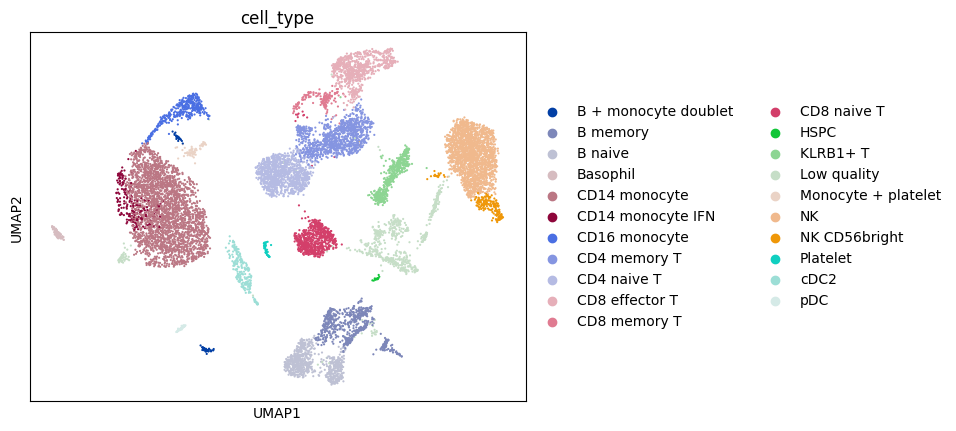

In [13]:
sc.pl.umap(rna, color="cell_type")

cell_type_palette = pd.Series(rna.uns["cell_type_colors"], index=rna.obs["cell_type"].cat.categories)
cell_type_signatures.uns["cell_type_colors"] = cell_type_palette.loc[
    cell_type_signatures.obs["cell_type"].cat.categories
].tolist()
cell_type_signatures.var["marker_of"] = pd.Categorical(
    cell_type_signatures.var["marker_of"], categories=cell_type_signatures.obs["cell_type"].cat.categories
)
cell_type_signatures.uns["marker_of_colors"] = cell_type_signatures.uns["cell_type_colors"]
cell_type_signatures.uns["lineage_colors"] = ["#4C78A8", "#F58518", "#54A24B", "#9D755D"]  # B, Myeloid, Other, T/NK
cell_type_signatures.uns["Data-Type_colors"] = ["#1E90FF", "#FFFF00"]  # prot, rna

mat_cell_types = dega.clust.Matrix(
    cell_type_signatures,
    col_attr=["cell_type", "lineage"],
    row_attr=["Data-Type", "marker_of"],
    col_entity={"entity": "cell", "attr": "cell_type"},
    name="citeseq_cell_types",
)
mat_cell_types.norm("row", by="zscore")
mat_cell_types.cluster()
cgm_cell_types = dega.viz.Clustergram(matrix=mat_cell_types, width=500, height=600)

landscape_cell_types = dega.viz.Landscape(
    technology="Chromium",
    base_url=DEGA_FILES_URL,
    adata=rna,
    cell_attr=["cell_type"],
    cluster_attr="cell_type",
    transform=np.eye(3),
    ini_zoom=-4.5,
    ini_x=5000,
    ini_y=5000,
)
linked_cell_types = dega.viz.spatial_clustergram(
    landscape_cell_types, cgm_cell_types, width="600px", height="800px"
)

In [14]:
linked_cell_types

Click a protein row such as `CD14_prot` or `CD45RA_prot` to color the UMAP by that protein, or a cell-type column to highlight its cells.

Genes and proteins of the same cell type sit side by side wherever the two modalities agree, for example the CD14 gene and protein in monocytes, or MS4A1 and the CD20 protein it encodes in B cells. Proteins also separate cells that RNA cannot: naive and memory T cells carry different isoforms of the CD45 protein, CD45RA and CD45RO, which come from a single gene, PTPRC, that the RNA probes detect in nearly every immune cell:

In [15]:
t_cell_types = ["CD4 naive T", "CD4 memory T", "CD8 naive T", "CD8 effector T"]
cd45 = pd.DataFrame(
    proteins[:, ["CD45RA_prot", "CD45RO_prot"]].X, columns=["CD45RA protein (CLR)", "CD45RO protein (CLR)"]
).groupby(proteins.obs["cell_type"].to_numpy()).mean()
cd45["PTPRC RNA detected (%)"] = (
    pd.Series(cells[:, "PTPRC"].layers["counts"].toarray().ravel() > 0).groupby(cells.obs["cell_type"].to_numpy()).mean()
    * 100
)
cd45.loc[t_cell_types].round(2)

,CD45RA protein (CLR),CD45RO protein (CLR),PTPRC RNA detected (%)
CD4 naive T,1.75,0.02,92.75
CD4 memory T,-0.12,1.16,93.10
CD8 naive T,2.28,-0.04,95.28
CD8 effector T,0.41,1.22,96.72


The Clustergram's column dendrogram also organizes the cell types into a hierarchy. Drag the column **dendrogram slider** to merge cell types into larger branches, or cut the same dendrogram with `Matrix.cut_tree`, its programmatic counterpart:

In [16]:
branches = mat_cell_types.cut_tree(axis="col", n_clusters=4)
cell_type_signatures.obs.assign(branch=branches).groupby("branch")["cell_type"].apply(lambda names: ", ".join(names))

branch
1    CD4 memory T, CD4 naive T, CD8 effector T, CD8...
2              B + monocyte doublet, B memory, B naive
3    Basophil, CD14 monocyte, CD14 monocyte IFN, CD...
4                                             Platelet
Name: cell_type, dtype: object

Cut into four branches, the dendrogram of cell-type signatures recovers the major blood lineages: T and NK cells, B cells (joined by the B + monocyte doublets, which carry B-cell proteins), myeloid cells, and platelets on their own. Moving the slider further splits these branches into individual cell types. The next level continues down the same hierarchy within B cells.

## Level 3: B cells at single-cell resolution

Cluster-level views average away differences between cells. To see what varies within B cells, we re-cluster the B cells that passed QC on their own, then cluster the individual cells in a Clustergram by their genes and proteins together.

In [17]:
b_cells = rna[rna.obs["cell_type"].isin(["B naive", "B memory"]).to_numpy()].copy()
sc.pp.highly_variable_genes(b_cells, n_top_genes=1000)
sc.tl.pca(b_cells, mask_var="highly_variable", random_state=0)
sc.pp.neighbors(b_cells, n_neighbors=15, n_pcs=20, random_state=0)
sc.tl.umap(b_cells, random_state=0)
sc.tl.leiden(
    b_cells, flavor="igraph", directed=False, n_iterations=2, resolution=0.6, random_state=0, key_added="b_leiden"
)

b_proteins = real_proteins[b_cells.obs_names].copy()
b_proteins.obs["b_leiden"] = b_cells.obs["b_leiden"]
sc.tl.rank_genes_groups(b_cells, groupby="b_leiden", method="wilcoxon", use_raw=False)
sc.tl.rank_genes_groups(b_proteins, groupby="b_leiden", method="wilcoxon", use_raw=False)
pd.DataFrame(
    {
        "cells": b_cells.obs["b_leiden"].value_counts().sort_index(),
        "top genes": sc.get.rank_genes_groups_df(b_cells, group=None)
        .groupby("group", observed=True)["names"].apply(lambda names: ", ".join(names[:6])),
        "top proteins": sc.get.rank_genes_groups_df(b_proteins, group=None)
        .groupby("group", observed=True)["names"].apply(lambda names: ", ".join(names[:6].str.removesuffix("_prot"))),
    }
)

,cells,top genes,top proteins
0,508,"FCER2, COL19A1, PLPP5, IGHD, IL4R, APLP2","CD23, CD184, CD73, HLA.DR, CD200, HLA.DR.DP.DQ"
1,189,"TCL1A, IGHD, NIBAN3, CD79B, CD38, PCDH9","CD38, CD10, CD9, IgD, IgM, CD5"
2,237,"TNFRSF13B, TBC1D9, MPEG1, IGHG1, CD24, NLRC5","CD24, CD45RA, CD1c, CD32, IgM, CD82"
3,79,"FGR, FCRL5, FCRL3, MS4A1, CCDC141, CD72","CD32, CD84, CD85j, CD20, CD19, CD52"
4,243,"NEK6, AIM2, TEX9, CRIP1, POU2AF1, COCH","HLA.ABC, CD82, CD35, CD99, CD267, CD49d"
5,8,"GLDC, TXNDC5, JCHAIN, PPIB, XBP1, MZB1","CD38, CD59, CD49d, CD43, CD86, CD312_EMR2"
6,80,"GIMAP7, GIMAP4, CD3E, FYB1, TRAC, ITK","CD7, CD2, CD49f, CD3, CD5, CD28"


Genes and proteins together identify the B-cell subtypes:

- **naive** B cells (FCER2 and its protein CD23, IGHD and IgD protein),
- **transitional** B cells (TCL1A; CD10 and CD38 proteins),
- **IgM memory** B cells resembling marginal-zone B cells (TNFRSF13B; CD1c, CD24, and IgM proteins),
- **atypical memory** B cells (FCRL5, FCRL3),
- **class-switched memory** B cells (AIM2, CRIP1, with little IgD or IgM protein),
- a few **plasmablasts** (JCHAIN, XBP1, MZB1; CD38 protein), and
- 80 cells that express T-cell genes and proteins (CD3E, TRAC; CD3, CD2, CD5, CD7) on top of B-cell ones.

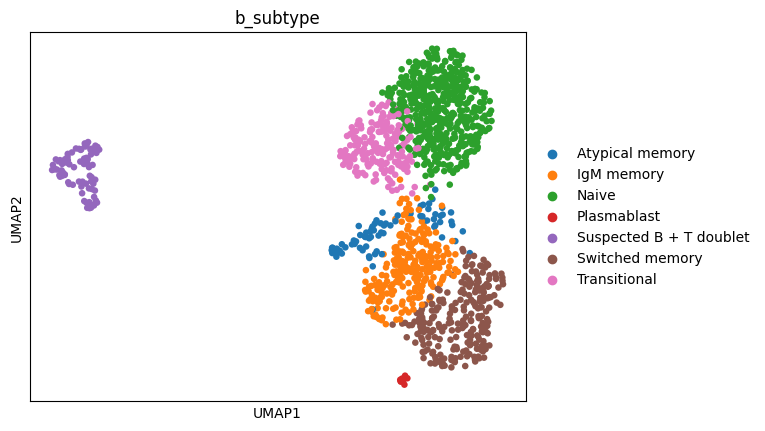

In [18]:
B_SUBTYPES = {
    "0": "Naive",
    "1": "Transitional",
    "2": "IgM memory",
    "3": "Atypical memory",
    "4": "Switched memory",
    "5": "Plasmablast",
    "6": "Suspected B + T doublet",
}
b_cells.obs["b_subtype"] = pd.Categorical(b_cells.obs["b_leiden"].astype(str).map(B_SUBTYPES))
b_proteins.obs["b_subtype"] = b_cells.obs["b_subtype"]
sc.pl.umap(b_cells, color="b_subtype")

The single-cell Clustergram below has the B cells as columns and, as rows, the top four marker genes and top four marker proteins of each subtype. Each row is z-scored across cells. Hierarchical clustering groups cells that share genes and proteins, and the column dendrogram lets you select a branch of cells to highlight in the B-cell UMAP.

In [19]:
sc.tl.rank_genes_groups(b_cells, groupby="b_subtype", method="wilcoxon", use_raw=False)
sc.tl.rank_genes_groups(b_proteins, groupby="b_subtype", method="wilcoxon", use_raw=False)
b_rna_features = top_features(b_cells, 4)
b_protein_features = top_features(b_proteins, 4)

b_single_cells = ad.concat(
    [
        ad.AnnData(
            b_cells[:, b_rna_features.index].X.toarray(),
            obs=b_cells.obs[["b_subtype"]],
            var=pd.DataFrame(index=b_rna_features.index),
        ),
        ad.AnnData(
            b_proteins[:, b_protein_features.index].X,
            obs=b_cells.obs[["b_subtype"]],
            var=pd.DataFrame(index=b_protein_features.index),
        ),
    ],
    axis="var",
    merge="first",
)
b_single_cells.var["Data-Type"] = pd.Categorical(
    ["rna"] * len(b_rna_features) + ["prot"] * len(b_protein_features), categories=["prot", "rna"]
)
b_single_cells.var["marker_of"] = pd.Categorical(
    pd.concat([b_rna_features, b_protein_features]).astype(str).to_numpy(),
    categories=b_cells.obs["b_subtype"].cat.categories,
)
b_single_cells.uns["b_subtype_colors"] = b_cells.uns["b_subtype_colors"]
b_single_cells.uns["marker_of_colors"] = b_cells.uns["b_subtype_colors"]
b_single_cells.uns["Data-Type_colors"] = ["#1E90FF", "#FFFF00"]

mat_b_cells = dega.clust.Matrix(
    b_single_cells,
    col_attr=["b_subtype"],
    row_attr=["Data-Type", "marker_of"],
    col_entity={"entity": "cell", "attr": "name"},
    name="citeseq_b_cells",
)
mat_b_cells.norm("row", by="zscore")
mat_b_cells.cluster()
cgm_b_cells = dega.viz.Clustergram(matrix=mat_b_cells, width=600, height=600)

landscape_b_cells = dega.viz.Landscape(
    technology="Chromium",
    base_url=DEGA_FILES_URL,
    adata=b_cells,
    cell_attr=["b_subtype"],
    cluster_attr="b_subtype",
    transform=np.eye(3),
    ini_zoom=-4.5,
    ini_x=5000,
    ini_y=5000,
)
linked_b_cells = dega.viz.spatial_clustergram(landscape_b_cells, cgm_b_cells, width="550px", height="800px")

In [20]:
linked_b_cells

## Suspected B + T doublets

The last group of 80 cells came from a cluster that looked like memory B cells at the cluster level and had about twice the counts of other B cells. Plotting one B-cell gene against one T-cell gene shows that these cells express both, as expected for a B cell and a T cell captured together in one droplet, or bound to each other:

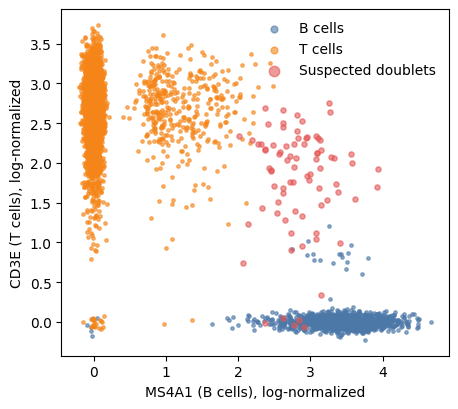

In [21]:
doublets = b_cells.obs_names[b_cells.obs["b_subtype"] == "Suspected B + T doublet"]
lineage = rna.obs["cell_type"].map(lineage_of)
group = pd.Series(pd.NA, index=rna.obs_names, dtype="object")
group[(lineage == "B").to_numpy()] = "B cells"
group[(lineage == "T/NK").to_numpy() & ~rna.obs["cell_type"].str.startswith("NK").to_numpy()] = "T cells"
group[doublets] = "Suspected doublets"

colors = {"B cells": "#4C78A8", "T cells": "#F58518", "Suspected doublets": "#E45756"}
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(5, 4.5))
for name, color in colors.items():
    members = group.index[group == name]
    expression = rna[members, ["MS4A1", "CD3E"]].X.toarray()
    jitter = rng.normal(0, 0.06, size=expression.shape)
    ax.scatter(*(expression + jitter).T, s=6 if name != "Suspected doublets" else 14, alpha=0.6, color=color, label=name)
ax.set_xlabel("MS4A1 (B cells), log-normalized")
ax.set_ylabel("CD3E (T cells), log-normalized")
ax.legend(frameon=False, markerscale=2)
plt.show()

The scatterplot compares one pair of markers. The Clustergram below compares a whole panel of B-cell, T-cell, NK, and myeloid genes and proteins across the suspected doublets and an equal number of randomly chosen B and T cells, all at once. Rows are colored by the lineage of each marker and by data type, and each row is z-scored across the compared cells.

In [22]:
MARKER_PANEL = {
    "B": ["MS4A1", "CD79A", "CD79B", "BANK1", "PAX5", "CD19_prot", "CD20_prot", "CD22_prot", "CD79b_prot"],
    "T": ["CD3E", "CD3D", "TRAC", "CD2", "LCK", "CD3_prot", "CD2_prot", "CD5_prot", "CD7_prot", "CD28_prot"],
    "NK": ["NKG7", "GNLY", "KLRD1", "PRF1", "CD56_prot", "CD16_prot", "NKp80_prot", "CD335_prot"],
    "Myeloid": ["LYZ", "S100A8", "S100A9", "CST3", "VCAN", "CD14_prot", "CD33_prot", "CD11b_prot", "CD64_prot"],
}
panel = pd.Series({feature: lineage for lineage, features in MARKER_PANEL.items() for feature in features})

reference = pd.concat(
    [group.index[group == name].to_series().sample(len(doublets), random_state=0) for name in ["B cells", "T cells"]]
)
compared = list(doublets) + list(reference.index)
genes = [feature for feature in panel.index if not feature.endswith("_prot")]
proteins_in_panel = [feature for feature in panel.index if feature.endswith("_prot")]

doublet_matrix = ad.AnnData(
    np.hstack([rna[compared, genes].X.toarray(), real_proteins[compared, proteins_in_panel].X]),
    obs=pd.DataFrame({"group": pd.Categorical(group[compared])}, index=compared),
    var=pd.DataFrame(
        {
            "lineage": pd.Categorical(panel[genes + proteins_in_panel], categories=list(MARKER_PANEL)),
            "Data-Type": pd.Categorical(["rna"] * len(genes) + ["prot"] * len(proteins_in_panel), categories=["prot", "rna"]),
        },
        index=genes + proteins_in_panel,
    ),
)
doublet_matrix.uns["group_colors"] = [colors[name] for name in doublet_matrix.obs["group"].cat.categories]
doublet_matrix.uns["lineage_colors"] = ["#4C78A8", "#F58518", "#B279A2", "#54A24B"]  # B, T, NK, Myeloid
doublet_matrix.uns["Data-Type_colors"] = ["#1E90FF", "#FFFF00"]

mat_doublets = dega.clust.Matrix(
    doublet_matrix,
    col_attr=["group"],
    row_attr=["lineage", "Data-Type"],
    col_entity={"entity": "cell", "attr": "name"},
    name="citeseq_doublets",
)
mat_doublets.norm("row", by="zscore")
mat_doublets.cluster()
cgm_doublets = dega.viz.Clustergram(matrix=mat_doublets, width=700, height=600)

In [23]:
cgm_doublets

Clustergram(category_colors={'B cells': '#4C78A8', 'Suspected doublets': '#E45756', 'T cells': '#F58518', 'B':…

Cutting the column dendrogram into three branches shows how the three groups of cells separate:

In [24]:
pd.crosstab(mat_doublets.cut_tree(axis="col", n_clusters=3), doublet_matrix.obs["group"])

group,B cells,Suspected doublets,T cells
cluster,,,
1,0,5,80
2,0,14,0
3,80,61,0


The suspected-doublet columns are high in both the B-cell and the T-cell rows, in RNA and protein alike, while their NK and myeloid rows stay low: each of these cells carries both programs, rather than some cells carrying one and some the other. One branch of the column dendrogram holds only suspected doublets, and most of the others sit next to the B cells, whose markers dominate their profile. Where a scatterplot shows one pair of markers at a time, the Clustergram makes the comparison across dozens of markers and hundreds of cells in parallel.

## Next steps

- Annotate cell types interactively with the Clustergram's manual categories, as in the original Clustergrammer2 notebooks.
- Explore other branches of the hierarchy at single-cell resolution, for example T cells, whose CD45RA and CD45RO proteins separate naive and memory states.
- See the [Chromium PBMC tutorial](../Scanpy_Chromium/) for RNA-only workflows and the [CST lung cancer tutorial](../CST_Lung_Cancer_PTM_Clustergram-Enrich/) for stacking other omics.